# 05 · Aprendizaje no supervisado

Este notebook explora el dataset del proyecto **sin usar las etiquetas** `Diagnosis` para entrenar. Aplica las técnicas del módulo:

- **PCA** para reducir dimensión, visualizar y quitar ruido.
- **K-Means** para segmentar a los pacientes en grupos de perfil clínico similar.
- **DBSCAN** como detector complementario de anomalías.

`Diagnosis` solo se utiliza al final, a modo de *post-hoc*, para interpretar qué representan los grupos. Los grupos no son categorías clínicas: son el inicio de una investigación.


## Carga y escalado

Se excluye `Sickness_Duration_Months` porque separa `Normal` de `Autoinmune` por construcción y dominaría los clusters. Las variables numéricas se estandarizan y `Gender` se codifica con one-hot.


In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from autoimmune_disorder_prediction.config import CLEANED_DATASET_PATH
from autoimmune_disorder_prediction.clustering import (
    cluster_profile,
    fit_dbscan,
    fit_kmeans,
    load_features,
    pca_variance,
    reduce_dimensions,
    scale_features,
    sweep_kmeans,
)

sns.set_theme(style="whitegrid", context="notebook", font="DejaVu Sans")

df = pd.read_parquet(CLEANED_DATASET_PATH)
X = load_features()
X_scaled = scale_features(X)

print(f"Pacientes: {len(df):,} | Variables usadas: {X.shape[1]}")
print(f"Matriz escalada: {X_scaled.shape}")


Pacientes: 12,500 | Variables usadas: 75
Matriz escalada: (12500, 76)


## 1. PCA: ¿cuántas dimensiones hay de verdad?

La varianza explicada acumulada indica cuántos componentes necesitamos para conservar el 80% y el 90% de la información. También se usan 2 componentes para visualizar a los pacientes en un plano.


Componentes para 80% de varianza: 39
Componentes para 90% de varianza: 48


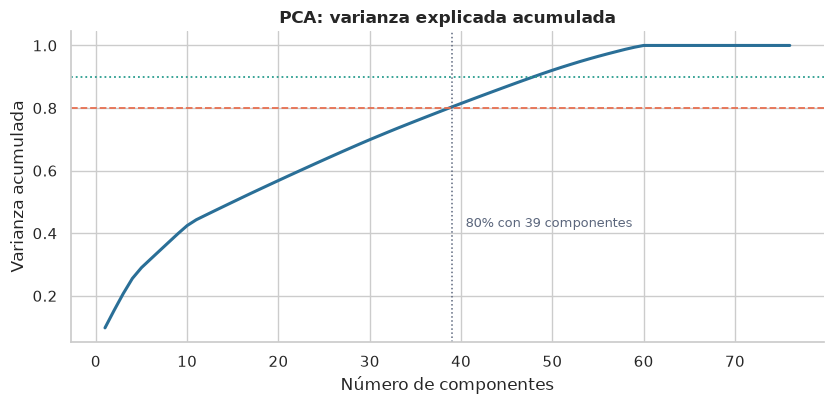

In [2]:
ratio, cumulative = pca_variance(X_scaled)
n_80 = int(np.searchsorted(cumulative, 0.80) + 1)
n_90 = int(np.searchsorted(cumulative, 0.90) + 1)
print(f"Componentes para 80% de varianza: {n_80}")
print(f"Componentes para 90% de varianza: {n_90}")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(range(1, len(cumulative) + 1), cumulative, color="#2A6F97", linewidth=2.2)
ax.axhline(0.80, color="#E76F51", linestyle="--", linewidth=1.3)
ax.axhline(0.90, color="#2A9D8F", linestyle=":", linewidth=1.3)
ax.axvline(n_80, color="#5C677D", linestyle=":", linewidth=1.1)
ax.text(n_80 + 1.5, 0.42, f"80% con {n_80} componentes", color="#5C677D", fontsize=9)
ax.set_xlabel("Número de componentes")
ax.set_ylabel("Varianza acumulada")
ax.set_title("PCA: varianza explicada acumulada", fontsize=12, fontweight="bold")
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


**Lectura.** Se necesitan alrededor de 39 componentes para el 80% y 48 para el 90% de la varianza. Hay mucha información distribuida: no existe un puñado de variables que resuma todo. Para clustering usaremos 20 componentes, un compromiso entre conservar señal y no arrastrar ruido; con demasiados componentes la silueta cae porque entra ruido.


## 2. K-Means: elegir k

El codo de la inercia y el coeficiente de silueta ayudan a elegir el número de grupos. La silueta mide qué tan bien asignado está cada punto a su cluster.


,k,inertia,silhouette
0,2,448809.734,0.309
1,3,398894.208,0.340
2,4,350565.679,0.313
3,5,323285.243,0.362
4,6,293395.651,0.360
5,7,256779.583,0.363
6,8,227381.214,0.409
7,9,203371.216,0.425
8,10,193929.189,0.228


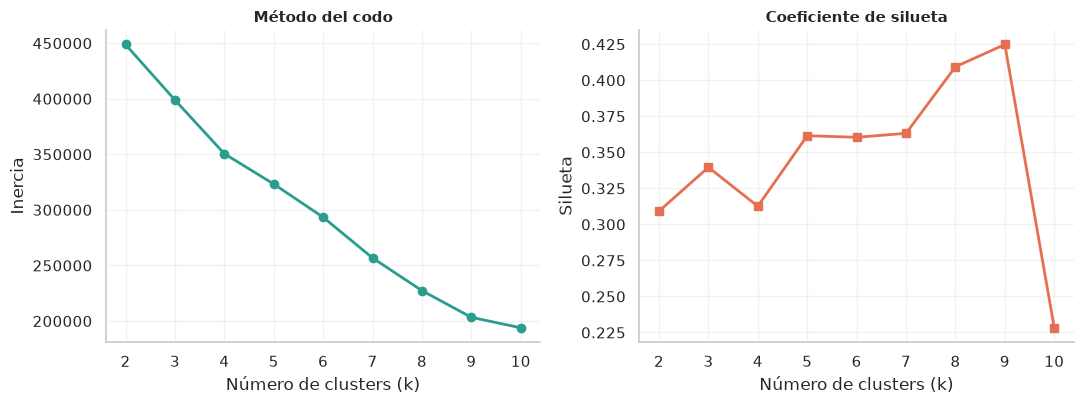

In [3]:
X_pca = reduce_dimensions(X_scaled, n_components=20)
sweep = sweep_kmeans(X_pca)
display(sweep.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].plot(sweep["k"], sweep["inertia"], marker="o", color="#2A9D8F", linewidth=2)
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inercia")
axes[0].set_title("Método del codo", fontsize=11, fontweight="bold")

axes[1].plot(sweep["k"], sweep["silhouette"], marker="s", color="#E76F51", linewidth=2)
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Silueta")
axes[1].set_title("Coeficiente de silueta", fontsize=11, fontweight="bold")

for ax in axes:
    ax.grid(alpha=0.25)
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()


**Lectura.** La inercia siempre baja al aumentar k, así que no decide sola. La silueta mejora con más grupos (hasta k = 9), pero k = 5 ofrece un equilibrio razonable y coincide con los 5 grupos del ejercicio de negocio. Elegimos **k = 5** por interpretabilidad, no porque sea el óptimo matemático: la decisión final es humana.


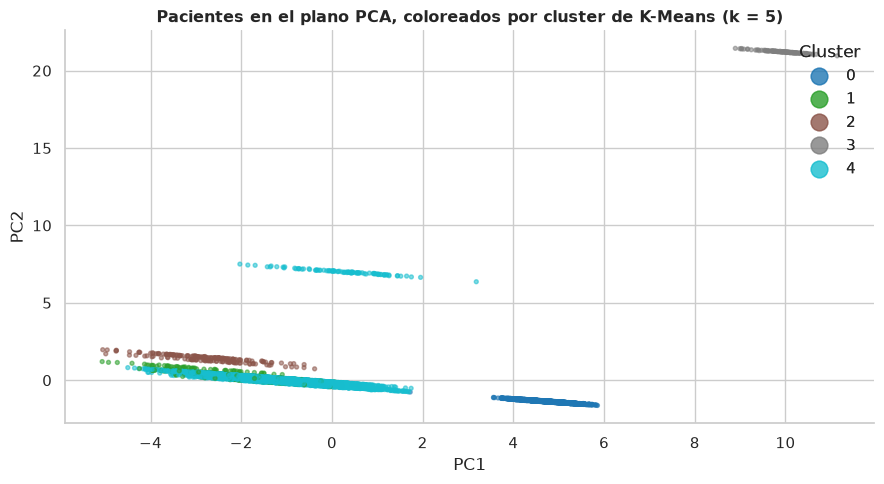

In [4]:
km = fit_kmeans(X_pca, n_clusters=5)
df["cluster_kmeans"] = km.labels_

X_2d = reduce_dimensions(X_scaled, n_components=2)
fig, ax = plt.subplots(figsize=(9, 5))
scatter = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=df["cluster_kmeans"], cmap="tab10", s=8, alpha=0.55)
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Pacientes en el plano PCA, coloreados por cluster de K-Means (k = 5)",
             fontsize=11.5, fontweight="bold")
legend = ax.legend(*scatter.legend_elements(), title="Cluster", frameon=False,
                   loc="upper right", markerscale=2)
ax.add_artist(legend)
sns.despine(ax=ax)
plt.tight_layout()
plt.show()


## 3. Interpretación post-hoc con las etiquetas reales

Las etiquetas no se usaron para entrenar. Ahora se comparan los clusters con `Diagnosis` para ver si tienen sentido clínico.


In [5]:
df["Grupo"] = np.where(df["Diagnosis"] == "Normal", "Normal", "Autoinmune")
display(pd.crosstab(df["cluster_kmeans"], df["Grupo"]))

for cluster in sorted(df["cluster_kmeans"].unique()):
    top = df.loc[df["cluster_kmeans"] == cluster, "Diagnosis"].value_counts().head(3)
    formatted = ", ".join(f"{name} ({count})" for name, count in top.items())
    print(f"Cluster {cluster}: {formatted}")


Grupo,Autoinmune,Normal
cluster_kmeans,,
0,1,2500
1,573,0
2,183,0
3,93,0
4,9150,0


Cluster 0: Normal (2500), Cogan syndrome (1)
Cluster 1: Bullous pemphigoid (88), Gestational pemphigoid (88), Autoimmune hepatitis (84)
Cluster 2: Dermatomyositis (183)
Cluster 3: Systemic Lupus Erythematosus (93)
Cluster 4: Endometriosis (184), Autoimmune oophoritis (170), Autoimmune orchitis (162)


**Lectura.** El cluster 0 es prácticamente el grupo `Normal` completo. Los clusters 2 y 3 aíslan enfermedades concretas (Dermatomiositis y Lupus, respectivamente) sin haber visto la etiqueta. Los clusters 1 y 4 agrupan al resto de los casos autoinmunes. Es decir, los grupos capturan perfiles clínicos, no solo diagnósticos: son candidatos a nombres como "perfil inflamatorio", "perfil normal" o "perfil específico".


## 4. Perfil clínico por cluster

Se comparan variables clave para ponerles nombre a los grupos.


In [6]:
profile_cols = ["Age", "CRP", "ESR", "Hemoglobin", "WBC_Count", "PLT_Count",
                "Sickness_Duration_Months"]
profile = cluster_profile(df, km.labels_, profile_cols)
display(profile)


,Age,CRP,ESR,Hemoglobin,WBC_Count,PLT_Count,Sickness_Duration_Months
cluster,,,,,,,
0,50.99,0.50,9.26,15.51,7777.20,293223.47,0.04
1,48.46,5.68,29.08,12.46,7882.57,293838.10,60.56
2,50.32,5.62,29.79,12.58,8164.16,308063.22,58.47
3,48.44,0.49,9.01,15.57,7735.15,299786.92,56.74
4,49.50,5.47,29.45,12.50,7958.66,300505.49,59.98


## 5. DBSCAN como detector de anomalías

DBSCAN no necesita `k`, pero sí `eps` y `min_samples`. Marca con -1 los puntos que no pertenecen a ninguna región densa: esos son los comportamientos atípicos.


In [7]:
db = fit_dbscan(X_pca, eps=2.0, min_samples=20)
df["cluster_dbscan"] = db.labels_
mask_noise = df["cluster_dbscan"] == -1
n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
print(f"Clusters detectados: {n_clusters}")
print(f"Ruido: {int(mask_noise.sum()):,} ({mask_noise.mean():.1%})")
display(pd.crosstab(df["cluster_dbscan"], df["Grupo"]))


Clusters detectados: 3
Ruido: 1,808 (14.5%)


Grupo,Autoinmune,Normal
cluster_dbscan,,
-1,1808,0
0,8100,0
1,92,0
2,0,2500


**Lectura.** DBSCAN separa el grupo `Normal` como una región muy densa y deja fuera a 1.808 pacientes autoinmunes como ruido. No sirve para segmentar enfermedades, pero sí para detectar comportamientos atípicos: en el caso de streaming, esos serían bots, cuentas compartidas o usuarios con patrones extremos que no conviene mezclar con los segmentos comerciales.


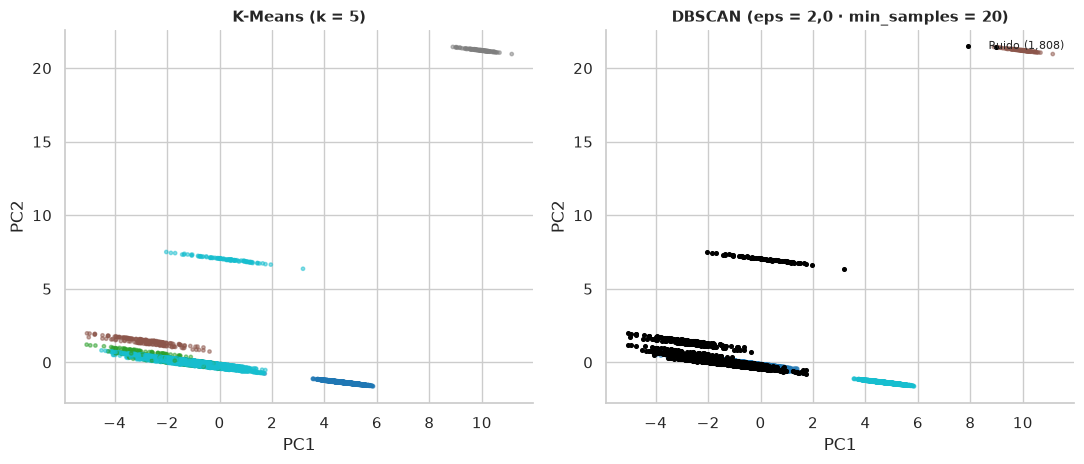

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

axes[0].scatter(X_2d[:, 0], X_2d[:, 1], c=df["cluster_kmeans"], cmap="tab10", s=6, alpha=0.5)
axes[0].set_title("K-Means (k = 5)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

axes[1].scatter(X_2d[~mask_noise, 0], X_2d[~mask_noise, 1],
                c=df.loc[~mask_noise, "cluster_dbscan"], cmap="tab10", s=6, alpha=0.5)
axes[1].scatter(X_2d[mask_noise, 0], X_2d[mask_noise, 1], c="black", s=7,
                label=f"Ruido ({int(mask_noise.sum()):,})")
axes[1].set_title("DBSCAN (eps = 2,0 · min_samples = 20)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].legend(frameon=False, fontsize=8, loc="upper right")

for ax in axes:
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()


## Conclusión

- PCA muestra que la información está repartida: 39 componentes para el 80% de la varianza. No hay una variable que resuma al paciente.
- K-Means con k = 5 separa un grupo casi puro de `Normal`, aísla dos enfermedades específicas (Dermatomiositis y Lupus) y agrupa al resto de los casos autoinmunes en dos perfiles inflamatorios.
- DBSCAN identifica `Normal` como una región densa y marca 1.808 autoinmunes como ruido: es útil como detector de anomalías, no como segmentador principal.
- **Advertencia:** estos grupos son exploratorios. No son diagnósticos, no se validaron externamente y dependen de la partición, del escalado y de la elección de k. Antes de usarlos en negocio habría que medir su estabilidad, perfilarlos con expertos y auditar sesgos por sexo y edad.
